processing data

In [14]:
import os
import cv2
import numpy as np
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

def load_and_preprocess_data(
    data_dir: str, 
    target_size:tuple = (224, 224) 
    ,validation_extension : tuple = ('.jpeg', '.jpg', '.bmp', '.png')
    ):
    images = []
    labels = []
    
    if not os.path.exists(data_dir):
        raise FileNotFoundError(f"The specified data directory '{data_dir}' does not exist.")
    
    class_names = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
    
    print(f"Found classes: {class_names} , with len : {len(class_names)}")
    
    corruputed_count = 0
    skipped_count = 0
    for label in class_names:
        class_dir = os.path.join(data_dir, label)
        file_list = os.listdir(class_dir)
        
        print(f"Processing class '{label}' with {len(file_list)} files.")
        
        for file_name in file_list:
            img_path = os.path.join(class_dir,file_name)
            ext = os.path.splitext(file_name)[1].lower()
            if ext not in validation_extension:
                try:
                    os.remove(img_path)
                    print(f"Removed file '{img_path}' due to invalid extension '{ext}'.")
                except Exception as e:
                    print(f"Error removing file '{img_path}': {e}")
                skipped_count += 1
                continue
            try:
                img = cv2.imread(img_path)
                
                if img is None:
                    print(f"[CORRUPTED] Could not read image '{img_path}'. Skipping.")
                    corruputed_count += 1
                    os.remove(img_path)
                    continue
                
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, target_size)
                images.append(img)
                labels.append(label)
                
            except Exception as e:
                print(f"[ERROR] An error occurred while processing image '{img_path}': {e}. Skipping.")
                if os.path.exists(img_path):
                    os.remove(img_path)
                skipped_count += 1

    print(f"Preprocessing complete. Corrupted images: {corruputed_count}, Skipped images: {skipped_count}.")
    
    images , labels = shuffle(images, labels, random_state=42)
    images_arr = np.array(images)
    labels_arr = np.array(labels)
    print(f"Final dataset shape: images {images_arr.shape}, labels {labels_arr.shape}")
    return images_arr, labels_arr ,class_names


images_arr, labels_arr, class_names = load_and_preprocess_data("../data/raw")


Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary'] , with len : 4
Processing class 'glioma' with 1621 files.
Processing class 'meningioma' with 1645 files.
Processing class 'notumor' with 2000 files.
Processing class 'pituitary' with 1757 files.
Preprocessing complete. Corrupted images: 0, Skipped images: 0.
Final dataset shape: images (7023, 224, 224, 3), labels (7023,)


Afficher graphiquement le nombre d’images dans chaque classe.

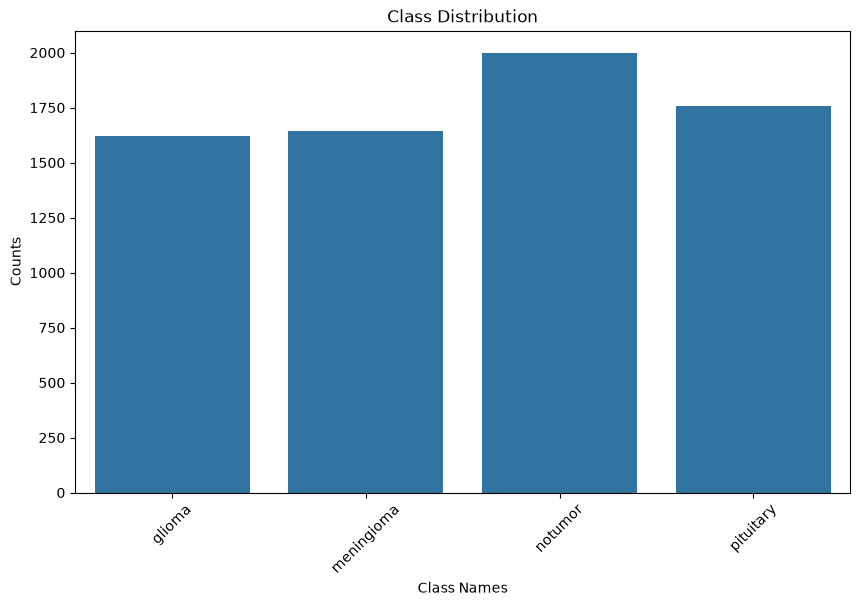

In [15]:
def plot_class_visualization(lavels_arr):
    class_names, counts = np.unique(lavels_arr, return_counts=True)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=class_names, y=counts)
    plt.title("Class Distribution")
    plt.xlabel("Class Names")
    plt.ylabel("Counts")
    plt.xticks(rotation=45)
        
plot_class_visualization(labels_arr)

Montrer un échantillon d’images pour chaque classe.

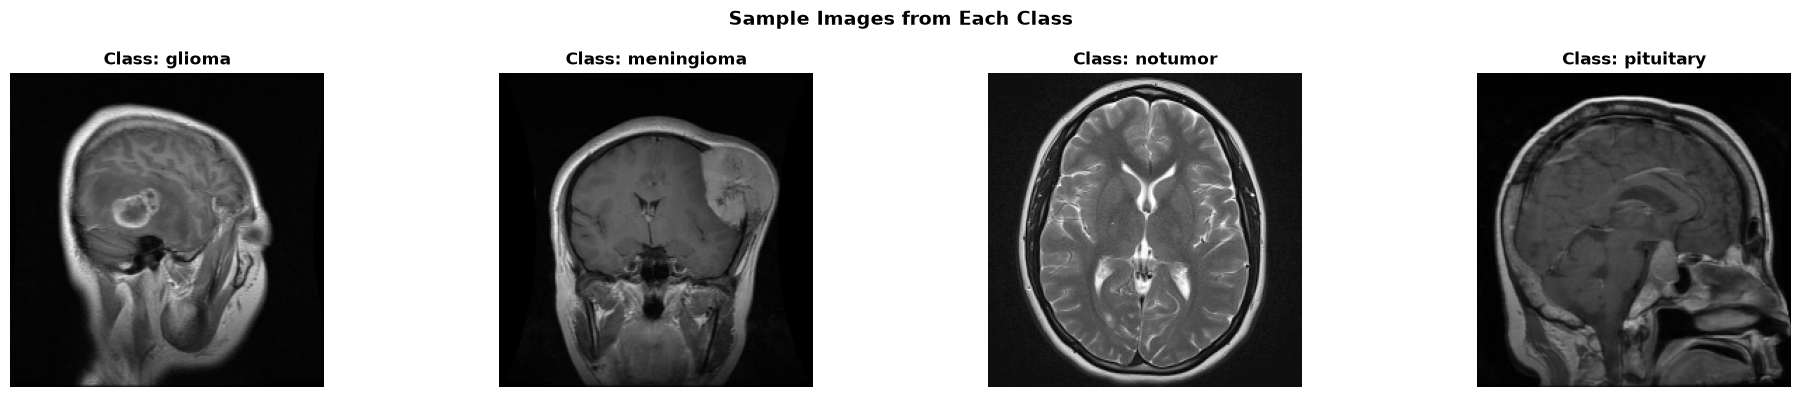

In [16]:
import matplotlib.pyplot as plt
import numpy as np

def display_sample_images(images_arr, labels_arr, class_names):

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    for i, cls in enumerate(class_names):
        indices = np.where(labels_arr == cls)[0]

        sample_index = indices[0]
        axes[i].imshow(images_arr[sample_index])
        axes[i].set_title(f"Class: {cls}", fontsize=12, fontweight='bold')
        axes[i].axis('off')

    plt.suptitle("Sample Images from Each Class", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_sample_images(images_arr, labels_arr, class_names)

Vérifier l’équilibre entre les classes et appliquer un rééquilibrage si nécessaire.

In [17]:
def check_class_balance(labels_arr):
    classes, counts = np.unique(labels_arr, return_counts=True)
    total_images = len(labels_arr)
    max_count = np.max(counts)
    min_count = np.min(counts)
    imbalance_ratio = max_count / min_count
    for cls, count in zip(classes, counts):
        percentage = (count / total_images) * 100
        print(f"Class '{cls}': {count} images ({percentage:.2f}%)")
    print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")
    if imbalance_ratio > 1.5:
        print("Warning: Significant class imbalance detected.")
    else:
        print("Class distribution is relatively balanced.")
    
check_class_balance(labels_arr)

Class 'glioma': 1621 images (23.08%)
Class 'meningioma': 1645 images (23.42%)
Class 'notumor': 2000 images (28.48%)
Class 'pituitary': 1757 images (25.02%)
Imbalance ratio (max/min): 1.23
Class distribution is relatively balanced.


Transformer les étiquettes textuelles en format numérique (ex. avec LabelEncoder ou to_categorical).

In [18]:
from sklearn.preprocessing import LabelEncoder

def encoder_labels(labels_arr):
    le = LabelEncoder()
    encoded_labels = le.fit_transform(labels_arr)
    return encoded_labels, le

encoded_labels, label_encoder = encoder_labels(labels_arr)
print("Encoded labels:", encoded_labels)
print("Label encoder:", label_encoder)

Encoded labels: [2 1 1 ... 2 3 0]
Label encoder: LabelEncoder()


Diviser les données en ensembles d’entraînement et de test.

In [19]:
from sklearn.model_selection import train_test_split
def split_classes(images_arr, y_encoded, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(images_arr, y_encoded, test_size=test_size, random_state=random_state, stratify=y_encoded)
    return X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = split_classes(images_arr, encoded_labels)

Normaliser les valeurs des pixels dans la plage [0, 1].

In [20]:


def normalize_pixel_value(X_train, X_test):
    X_train_norm = X_train.astype('float32') / 255.0
    X_test_norm = X_test.astype('float32') / 255.0
    return X_train_norm, X_test_norm

normalized_X_train, normalized_X_test = normalize_pixel_value(X_train, X_test)


Définir l’architecture CNN (Conv2D + MaxPooling + Dropout + Dense) avec des paramètres optimaux.
Choisir les meilleures fonctions d’activation pour les couches cachées et la couche de sortie.

In [21]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_brainscan_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),
        
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.50),
        layers.Dense(4, activation='softmax')
    ])
    return model


Compiler le modèle (ex. : Optimiseur Adam, fonction de perte categorical_crossentropy).


In [22]:
from matplotlib.pyplot import plot


model = build_brainscan_cnn()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



Utiliser les fonctions model.summary() et plot_model() pour vérifier l’architecture du modèle.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

None


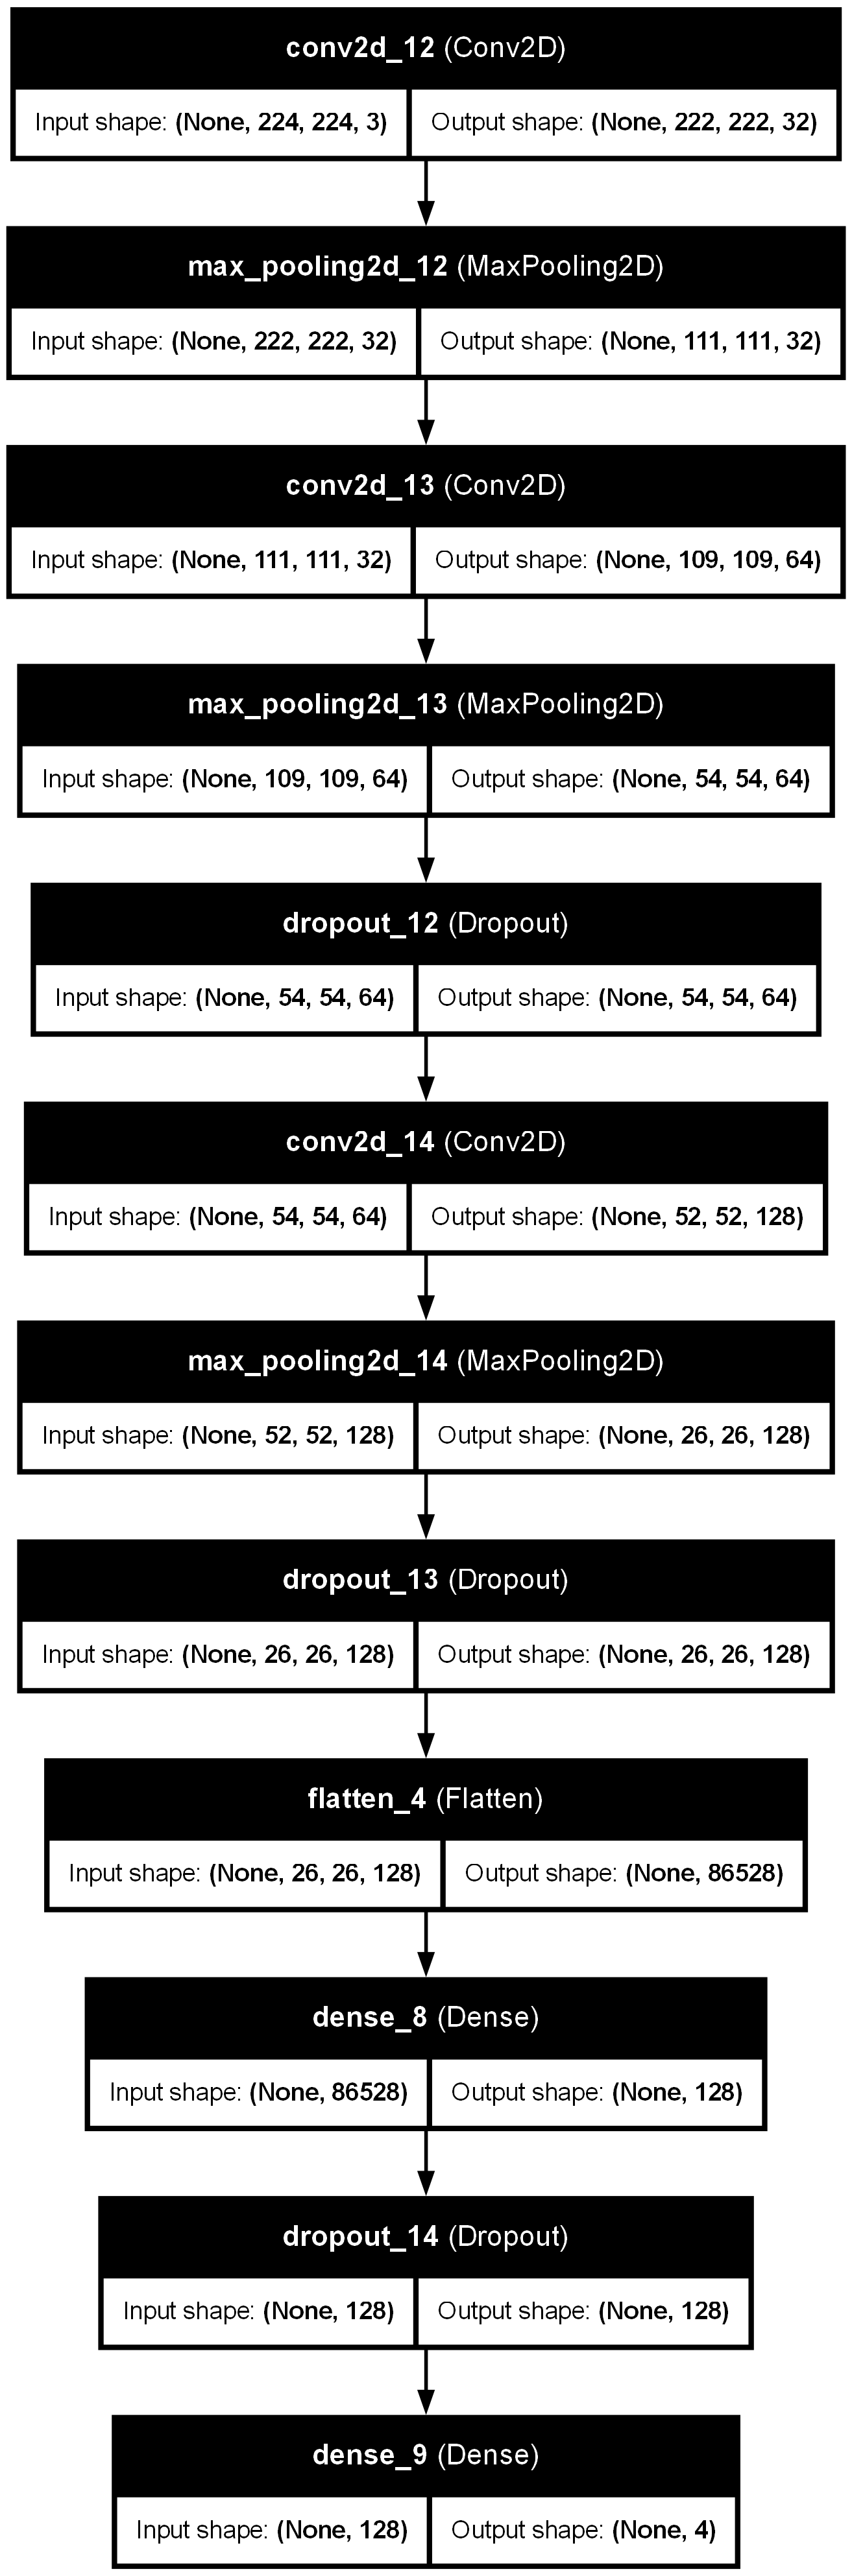

In [23]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image

print(model.summary())

plot_model(
    model, 
    to_file='brainscan_cnn_architecture.png', 
    show_shapes=True, 
    show_layer_names=True
)

Image(filename='brainscan_cnn_architecture.png')

Déterminer les hyperparamètres (taux d’apprentissage, nombre d’époques, taille de batch).

Model compiled successfully.

Starting training...
Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.6420 - loss: 0.9154

176/176 ━━━━━━━━━━━━━━━━━━━━ 76s 389ms/step - accuracy: 0.6420 - loss: 0.9154 - val_accuracy: 0.8313 - val_loss: 0.4521
Epoch 2/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.8330 - loss: 0.4348

176/176 ━━━━━━━━━━━━━━━━━━━━ 62s 353ms/step - accuracy: 0.8330 - loss: 0.4348 - val_accuracy: 0.8719 - val_loss: 0.3275
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.8896 - loss: 0.3066

176/176 ━━━━━━━━━━━━━━━━━━━━ 60s 340ms/step - accuracy: 0.8896 - loss: 0.3066 - val_accuracy: 0.9103 - val_loss: 0.2463
Epoch 4/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 326ms/step - accuracy: 0.9098 - loss: 0.2357

176/176 ━━━━━━━━━━━━━━━━━━━━ 61s 348ms/step - accuracy: 0.9098 - loss: 0.2357 - val_accuracy: 0.9160 - val_loss: 0.2207
Epoch 5/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step - accuracy: 0.9372 - loss: 0.1859

...

 Total params: 33,508,430 (127.82 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,954 (85.22 MB)

None
Training history: {'accuracy': [0.64204341173172, 0.8330366611480713, 0.8896404504776001, 0.9097543358802795, 0.9371662735939026, 0.9455322027206421, 0.9528301954269409, 0.959594190120697, 0.9658241271972656, 0.9740120768547058, 0.9798860549926758], 'loss': [0.9153693318367004, 0.43480971455574036, 0.30662810802459717, 0.2357252687215805, 0.18587785959243774, 0.14271476864814758, 0.11812469363212585, 0.10627806931734085, 0.09165028482675552, 0.07891718298196793, 0.054507844150066376], 'val_accuracy': [0.8313167095184326, 0.871886134147644, 0.9103202819824219, 0.9160142540931702, 0.9288256168365479, 0.9466192126274109, 0.9601423740386963, 0.9615658521652222, 0.9565836191177368, 0.9608541131019592, 0.9651245474815369], 'val_loss': [0.45213428139686584, 0.3274577558040619, 0.24629753828048706, 0.22068209946155548, 0.20034989714622498, 0.16827210783958435, 0.15261302888393402, 0.13465610146522522, 0.13816185295581818, 0.14844731986522675, 0.16685892641544342]}


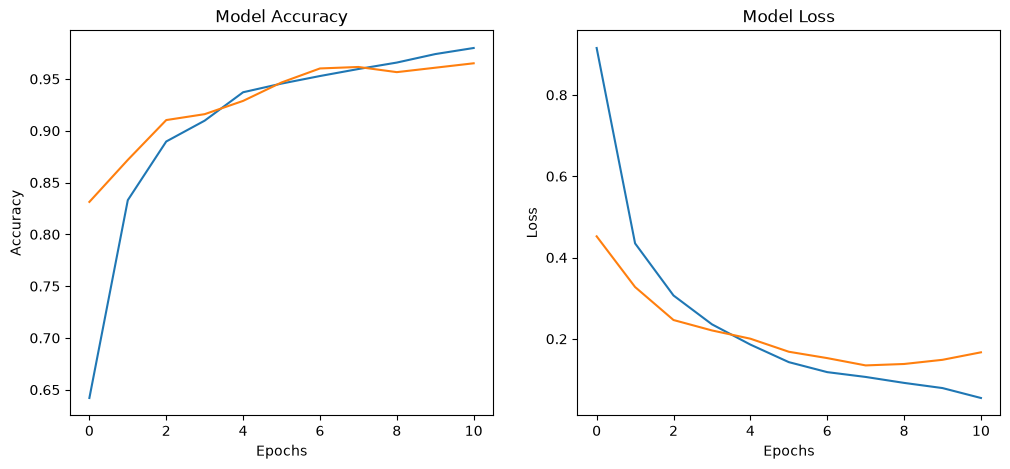

In [32]:
import time 
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping ,ModelCheckpoint

def adjust_hyperparameters(X_train, y_train, X_test, y_test, learning_rate=0.001, EPOCHS=20 , batch_size=32 , callbacks=None):
    model = build_brainscan_cnn()
    
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    
    model.compile(
        optimizer=optimizer, 
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    print("Model compiled successfully.")
    
    print("\nStarting training...")
    start_time = time.time()
    
    history = model.fit(
        x=X_train, 
        y=y_train,
        epochs=EPOCHS, 
        callbacks=callbacks,
        batch_size=batch_size,
        validation_data=(X_test, y_test)
    )
    
    end_time = time.time()
    total_seconds = end_time - start_time
    print(f"\nTraining completed in {total_seconds:.2f} seconds.")
    
    return model, history

early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

checkpoint_callback = ModelCheckpoint(
    filepath="brain_tumor_detector.h5", 
    monitor='val_loss', 
    save_best_only=True
)

model, history = adjust_hyperparameters(
    X_train=normalized_X_train, 
    y_train=y_train, 
    X_test=normalized_X_test, 
    y_test=y_test,
    learning_rate=0.001, 
    EPOCHS=20,
    callbacks=[early_stopping, checkpoint_callback]
)

print("Model training completed successfully.")
print(model.summary())
print("Training history:", history.history)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

